In [1]:
import numpy as np
import pandas as pd 
import matplotlib.pyplot as plt
from scipy.stats import norm
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import ConstantKernel, RBF

In [ ]:
# Original dataset has 15 rows

In [2]:
X = np.load(r"initial_data\function_3\initial_inputs.npy")
Y = np.load(r"initial_data\function_3\initial_outputs.npy")
# Converting the data into a more readable format
df = pd.DataFrame({
    'x1': X[:,0],
    'x2': X[:,1],
    'x3': X[:,2],
    'y': Y
})
df.index = df.index+1
df


,x1,x2,x3,y
1,0.171525,0.343917,0.248737,-0.112122
2,0.242114,0.644074,0.272433,-0.087963
3,0.534906,0.398501,0.173389,-0.111415
4,0.492581,0.611593,0.340176,-0.034835
5,0.134622,0.219917,0.458206,-0.048008
6,0.345523,0.941360,0.269363,-0.110621
7,0.151837,0.439991,0.990882,-0.398926
8,0.645503,0.397143,0.919771,-0.113869
9,0.746912,0.284196,0.226300,-0.131461
10,0.170477,0.697032,0.149169,-0.094190


In [6]:
print(f'Best output value so far:\n {max(Y)}')
print(f'Corresponding x values:\n {X[np.argmax(Y)]}')
print(f'Best query output: \n Query {np.argmax(Y[15:])+1}: {max(Y[15:])}')
print(f'Improvement over last:\n {max(Y)} - {max(Y[:(len(Y)-1)])} = {max(Y)-max(Y[:(len(Y)-1)])}')

Best output value so far:
 -0.0030998706914343163
Corresponding x values:
 [0.313581 0.474345 0.485191]
Best query output: 
 Query 7: -0.0030998706914343163
Improvement over last:
 -0.0030998706914343163 - -0.0030998706914343163 = 0.0


In [3]:
# Define the GP kernel: a constant (signal variance) scaling an RBF (smoothness) kernel.
# length_scale=0.2 is the starting guess; it gets tuned during fitting.
kernel = ConstantKernel(1.0) * RBF(length_scale=0.2)
gp = GaussianProcessRegressor(
    kernel=kernel,
    alpha=1e-10,              # Tiny noise term added to the diagonal for numerical stability
    normalize_y=True,         # Standardise Y (zero mean, unit variance) before fitting
    n_restarts_optimizer=20,  # Re-run hyperparameter optimisation from 20 random starts to avoid poor local optima
    random_state = 42         # Fixes the random restarts so results are reproducible
)

# Fit the GP to the observed inputs (X) and outputs (Y)
gp.fit(X, Y)

# Randomly sample 10,000 candidate points in the 3-dimensional input space
candidate_points = np.random.rand(10000,3)

# Get the GP's predicted mean and standard deviation (uncertainty) at each candidate
mu, sigma = gp.predict(candidate_points, return_std=True)

# Best observed value so far (we are maximising)
best_y = np.max(Y)
xi = 0   # Exploration parameter: larger values push the search towards more uncertain regions

# Expected gain of each candidate over the current best
improvement = mu - best_y - xi

# Standardised improvement (Z-score), computed only where sigma > 0 to avoid division by zero
Z = np.zeros_like(mu)
mask = sigma > 0
Z[mask] = improvement[mask] / sigma[mask]

# Expected Improvement (EI) formula:
#   improvement * CDF(Z)  -> exploitation (high predicted mean)
#   sigma * PDF(Z)        -> exploration (high uncertainty)
# Points with zero uncertainty keep EI = 0
EI = np.zeros_like(mu)
EI[mask] = (
    improvement[mask] * norm.cdf(Z[mask])
    + sigma[mask] * norm.pdf(Z[mask])
)

# Pick the candidate with the highest EI as the next point to query
next_point = candidate_points[np.argmax(EI)]

print("Next point:", np.round(next_point, 6))

# Sanity check: the GP's prediction at the chosen point
mean, std = gp.predict(next_point.reshape(-1,3), return_std=True)
print(f'Predicted mean: {mean}')
print(f'Predicted std: {std}')

Next point: [0.436373 0.45349  0.563487]
Predicted mean: [-0.00786535]
Predicted std: [0.0301281]


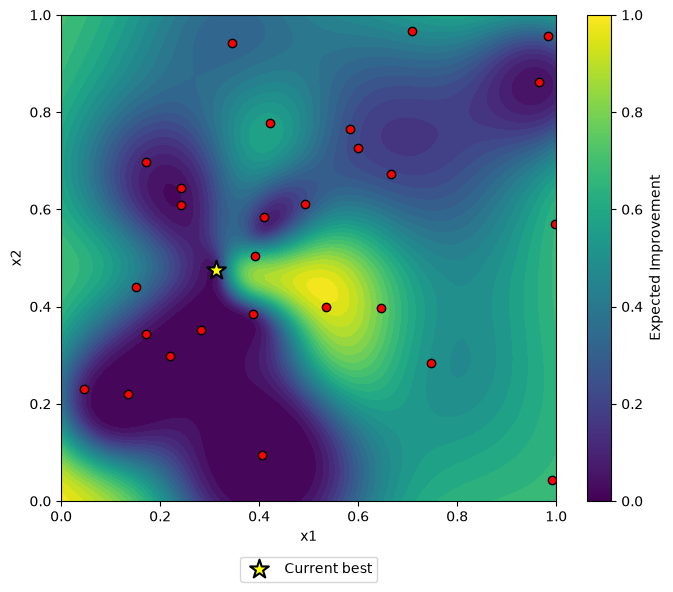

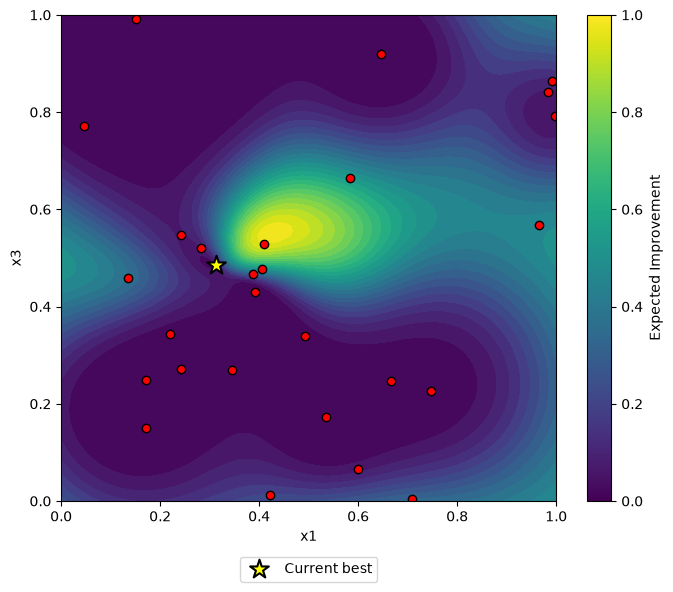

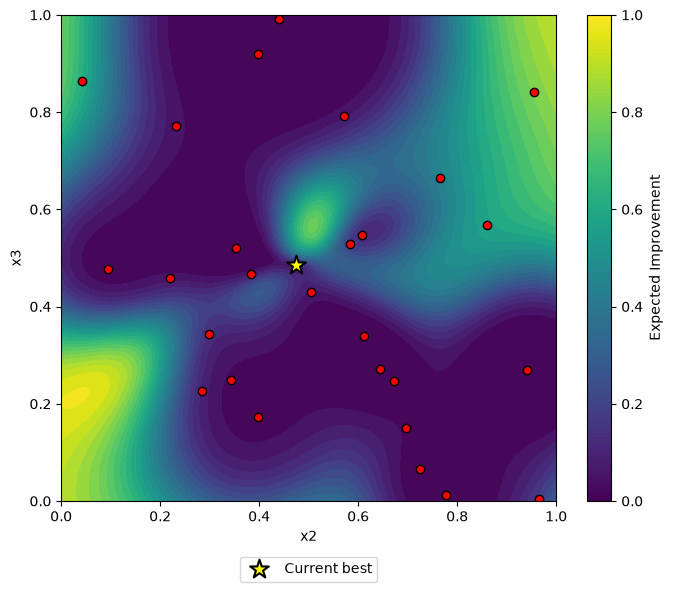

In [ ]:
def plot_EI_slice(gp, X, Y, dim1=0, dim2=1, resolution=100, xi=0):
    """
    Plot a 2D slice of the Expected Improvement acquisition function.

    Parameters
    ----------
    gp : fitted GaussianProcessRegressor
    X : observed inputs (n_samples, n_features)
    Y : observed outputs
    dim1 : first variable to plot
    dim2 : second variable to plot
    """

    # Use the best observed point as the "background": all dimensions not being
    # plotted are held fixed at this point's values
    best_point = X[np.argmax(Y)].copy()

    # Build a regular grid over the unit square for the two chosen dimensions
    x = np.linspace(0, 1, resolution)
    y = np.linspace(0, 1, resolution)

    xx, yy = np.meshgrid(x, y)

    # Create one full-dimensional row per grid cell, each starting as a copy of best_point
    grid = np.tile(best_point, (xx.size, 1))

    # Overwrite just the two plotted dimensions with the grid coordinates
    grid[:, dim1] = xx.ravel()
    grid[:, dim2] = yy.ravel()

    # GP predicted mean and uncertainty at every grid point
    mu, sigma = gp.predict(grid, return_std=True)

    # Best observed value so far (we are maximising)
    best_y = np.max(Y)

    # Expected gain of each grid point over the current best
    improvement = mu - best_y - xi

    EI = np.zeros_like(mu)

    mask = sigma > 0

    # Standardised improvement (Z-score)
    Z = np.zeros_like(mu)
    Z[mask] = improvement[mask] / sigma[mask]

    # Expected Improvement: exploitation term (CDF) + exploration term (PDF)
    EI[mask] = (
        improvement[mask] * norm.cdf(Z[mask])
        + sigma[mask] * norm.pdf(Z[mask])
    )

    plt.figure(figsize=(7,6))

    # Filled contour map of EI across the slice (brighter = higher EI)
    plt.contourf(xx, yy, EI.reshape(xx.shape), levels=30, cmap="viridis")

    # Overlay all observed points, projected onto the two plotted dimensions
    plt.scatter(
        X[:, dim1],
        X[:, dim2],
        c="red",
        edgecolor="black"
    )

    # Highlight the best observed point with a large yellow star
    plt.scatter(
    best_point[dim1],
    best_point[dim2],
    c="yellow",
    edgecolor="black",
    s=200,
    marker="*",
    linewidth=1.5,
    label="Current best"
    )

    plt.xlabel(f"x{dim1+1}")
    plt.ylabel(f"x{dim2+1}")

    plt.colorbar(label="Expected Improvement")
    plt.legend(loc="upper center", bbox_to_anchor=(0.5, -0.1))
    plt.tight_layout()
    plt.show()

plot_EI_slice(gp, X, Y, dim1=0, dim2=1)
plot_EI_slice(gp, X, Y, dim1=0, dim2=2)
plot_EI_slice(gp, X, Y, dim1=1, dim2=2)

In [ ]:
'''
1st point selected: [0.387781-0.383893-0.466712]
Output: -0.005550983212420927

2nd point selected: [0.406345-0.094218-0.477015]
Output: -0.08737205881194857

3rd point selected: [0.422095-0.777389-0.013354]
Output: -0.08102340742936227

4th point selected: [0.410675-0.583227-0.527665]
Output: -0.00943402992891043

5th point selected: [0.707859-0.965973-0.003964]
Output: -0.12082192320572424

6th point selected: [0.584339-0.765489-0.665115]
Output: -0.1050003024087159

7th point selected: [0.313581-0.474345-0.485191]
Output: -0.0030998706914343163   ---NEW BEST---

8th point selected: [0.984142-0.955934-0.841888]
Output: -0.05698622539214811

9th point selected: [0.997763-0.570339-0.791631]
Output: -0.06772925147099262 

10th point selected: [0.992192-0.042599-0.864089]
Output: -0.11082703456747281 

11th point selected: [0.391551-0.504241-0.429286]
Output: -0.013965041521816681 

12th point selected: [0.282739-0.352652-0.521176]
Output: -0.04141401605917263 

Final point selected: [0.241998-0.608233-0.546142]   --- xi reduced to 0 ---
Output: -0.032599958155336145

In [ ]:
# Updating data with new input-output pairs 

# X_query1 = np.array([0.387781,0.383893,0.466712], dtype=np.float64)
# Y_query1_output = np.array([-0.005550983212420927], dtype=np.float64)
# X_updated = np.vstack((X, X_query1))
# Y_updated = np.append(Y, Y_query1_output)

# X_query2 = np.array([0.406345,0.094218,0.477015], dtype=np.float64)
# Y_query2_output = np.array([-0.08737205881194857], dtype=np.float64)
# X_updated = np.vstack((X, X_query2))
# Y_updated = np.append(Y, Y_query2_output)

# X_query3 = np.array([0.422095,0.777389,0.013354], dtype=np.float64)
# Y_query3_output = np.array([-0.08102340742936227], dtype=np.float64)
# X_updated = np.vstack((X, X_query3))
# Y_updated = np.append(Y, Y_query3_output)

# X_query4 = np.array([0.410675,0.583227,0.527665], dtype=np.float64)
# Y_query4_output = np.array([-0.00943402992891043], dtype=np.float64)
# X_updated = np.vstack((X, X_query4))
# Y_updated = np.append(Y, Y_query4_output)

# X_query5 = np.array([0.707859,0.965973,0.003964], dtype=np.float64)
# Y_query5_output = np.array([-0.12082192320572424], dtype=np.float64)
# X_updated = np.vstack((X, X_query5))
# Y_updated = np.append(Y, Y_query5_output)

# X_query6 = np.array([0.584339,0.765489,0.665115], dtype=np.float64)
# Y_query6_output = np.array([-0.1050003024087159], dtype=np.float64)
# X_updated = np.vstack((X, X_query6))
# Y_updated = np.append(Y, Y_query6_output)

# X_query7 = np.array([0.313581,0.474345,0.485191], dtype=np.float64)
# Y_query7_output = np.array([-0.0030998706914343163], dtype=np.float64)
# X_updated = np.vstack((X, X_query7))
# Y_updated = np.append(Y, Y_query7_output)

# X_query8 = np.array([0.984142,0.955934,0.841888], dtype=np.float64)
# Y_query8_output = np.array([-0.05698622539214811], dtype=np.float64)
# X_updated = np.vstack((X, X_query8))
# Y_updated = np.append(Y, Y_query8_output)

# X_query9 = np.array([0.997763,0.570339,0.791631], dtype=np.float64)
# Y_query9_output = np.array([-0.06772925147099262], dtype=np.float64)
# X_updated = np.vstack((X, X_query9))
# Y_updated = np.append(Y, Y_query9_output)

# X_query10 = np.array([0.992192,0.042599,0.864089], dtype=np.float64)
# Y_query10_output = np.array([-0.11082703456747281], dtype=np.float64)
# X_updated = np.vstack((X, X_query10))
# Y_updated = np.append(Y, Y_query10_output)

# X_query11 = np.array([0.391551,0.504241,0.429286], dtype=np.float64)
# Y_query11_output = np.array([-0.013965041521816681], dtype=np.float64)
# X_updated = np.vstack((X, X_query11))
# Y_updated = np.append(Y, Y_query11_output)

# X_query12 = np.array([0.282739,0.352652,0.521176], dtype=np.float64)
# Y_query12_output = np.array([-0.04141401605917263], dtype=np.float64)
# X_updated = np.vstack((X, X_query12))
# Y_updated = np.append(Y, Y_query12_output)

# X_query13 = np.array([0.241998,0.608233,0.546142], dtype=np.float64)
# Y_query13_output = np.array([-0.032599958155336145], dtype=np.float64)
# X_updated = np.vstack((X, X_query13))
# Y_updated = np.append(Y, Y_query13_output)

In [ ]:
# Save new data to original files (initial_inputs.npy & initial_outputs.npy)

# np.save(r"initial_data\function_3\initial_inputs.npy", X_updated)
# np.save(r"initial_data\function_3\initial_outputs.npy", Y_updated)